# Function 2 - Week 5: Cohort Exploration Review

#### Review of Measured Outputs and Input Coverage using Official Returns through Week 4, received on **23 October 2026**, and the retained **20 October 2026** Cohort Snapshot.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_output_number_line, plot_sampling_gaps,
    plot_observed_terrain, plot_fixed_exploration_progression,
)
from cohort_review_helpers import load_cohort_review
from noise_review_helpers import nearby_output_differences
from model_review_plots import plot_nearby_differences

In [2]:
# Settings for this run. Keep the saved planning coordinates at full precision.
FUNCTION_NUMBER = 2
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}

ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
OFFICIAL_DATA_PATH = ANALYSIS_DIR.parent / "official" / "observations.csv"
EXPECTED_PEER_COUNT = 5
PEER_ROUND_MAX = 2
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK} cohort"
NOISE_ASSUMPTION_FRACTION = 0.10
CLOSEST_PAIRS_TO_SHOW = 8
NOISE_PLOT_SETTINGS = dict(maximum_distance=0.10, figsize=(12, 5))

FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
NOISE_PAIR_SETTINGS = dict(cutoffs=(0.015, 0.03, 0.05, 0.10), precision=PORTAL_DECIMALS)
PLANNED_QUERIES = pd.DataFrame([
    [0.22823414192856306, 0.06664413600559765],
    [0.8355651699511926, 0.23291097243365763],
    [0.17953980688500848, 0.8087368655610445],
], columns=INPUT_COLUMNS)

SAMPLING_GAP_SIZE = (7.6 * 0.75, 6.1 * 0.75)
TERRAIN_SETTINGS = dict(
    relief=0.16, width=850, height=560,
    camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)

In [3]:
# Validate the pooled records against the official snapshot; retain the owner's timeline.
review = load_cohort_review(
    DATA_PATH, OFFICIAL_DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
    expected_peer_count=EXPECTED_PEER_COUNT, peer_round_max=PEER_ROUND_MAX,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["data"].loc[review["peer_mask"]])
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,y
14,peer-kosina-round-01,1,0.963166,0.929385,-0.025704
15,peer-kosina-round-02,2,0.690829,0.926564,0.592732
16,peer-mkamar17-round-01,1,0.799891,0.925328,0.037881
17,peer-tomxandrews-round-01,1,0.725000,0.945000,0.506702
18,peer-arwelbrown-round-02,2,0.164182,0.178150,-0.065624


,observation_id,source_round,x1,x2,y,output_rank
13,round-04,4,0.17954,0.808737,0.131194,11


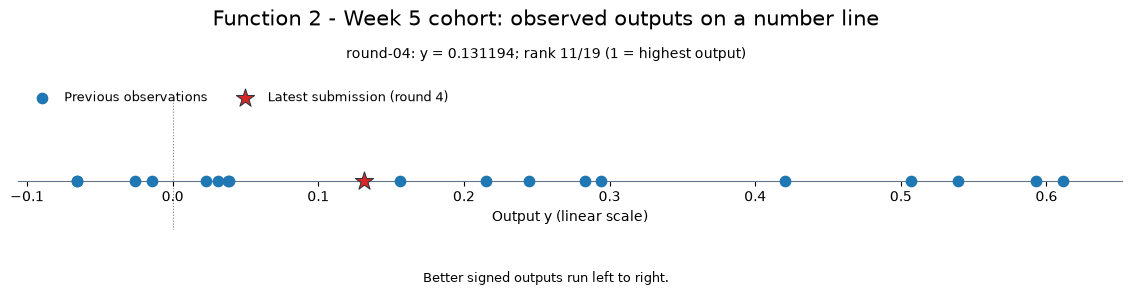

In [4]:
# Outputs on their original linear scale.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

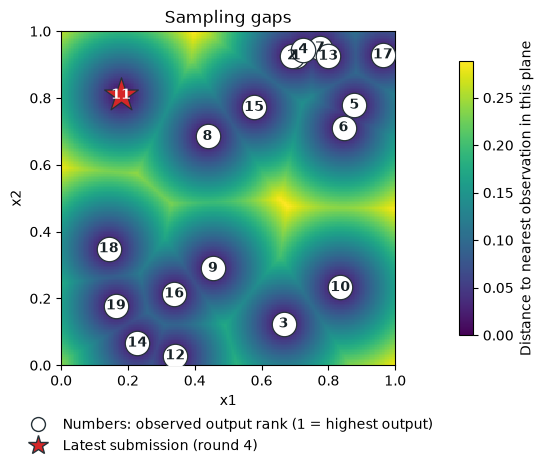

In [5]:
# Measured ranks and sampling gaps in the two-input square.
plot_sampling_gaps(
    review["plot_data"], pair=INPUT_COLUMNS,
    highlight=review["latest_mask"],
    highlight_label=f"Latest submission (round {review['latest_round']})",
    figsize=SAMPLING_GAP_SIZE, save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [6]:
# This renderer joins measured heights; it does not fit a model.
terrain_fig = plot_observed_terrain(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed-output terrain ({len(review['data'])} samples)",
    save_to=FIGURES_DIR / "observed-output-terrain.html", **TERRAIN_SETTINGS,
)
terrain_fig.show(config={**PLOT_CONFIG, "responsive": TERRAIN_SETTINGS["width"] is None})

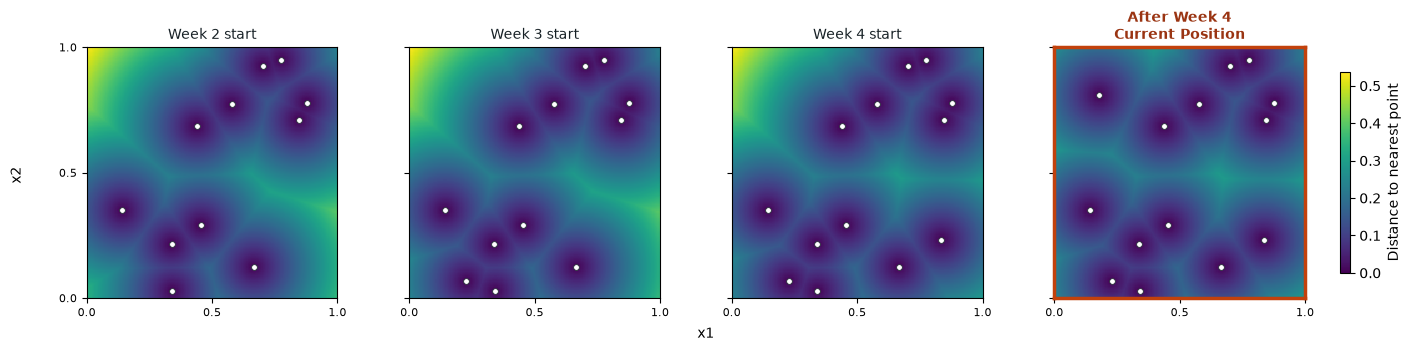

In [7]:
# Use official history only; peer round labels are not an owner query timeline.
plot_fixed_exploration_progression(
    review["own_data"], PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK,
    save_to=FIGURES_DIR / "fixed-exploration-progression.png",
)

In [8]:
# An empty table means the predetermined shortlist has no remaining query.
remaining_queries = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_queries.style.format({
    column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS
}))

,x1,x2,Portal input
Week,,,


In [9]:
# Full-space pairs include every coordinate, even when a fitted model omits one.
noise_pairs = nearby_output_differences(
    review["data"], input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN, **NOISE_PAIR_SETTINGS,
)
display(pd.Series(noise_pairs["summary"]))
display(noise_pairs["pairs"].head(CLOSEST_PAIRS_TO_SHOW).round(6))
display(noise_pairs["cutoffs"].round(6))
plot_nearby_differences(
    noise_pairs, assumed_noise_sd=NOISE_ASSUMPTION_FRACTION * noise_pairs["summary"]["output_sd"],
    title=f"{TITLE}: nearby-point noise diagnostics", **NOISE_PLOT_SETTINGS,
    save_to=FIGURES_DIR / "noise-neighbours.png",
)
print(json.dumps({"analysis": "nearby_point_noise_diagnostic", **noise_pairs["summary"],
                  "cutoff_sensitivity": noise_pairs["cutoffs"].to_dict(orient="records")}, indent=2))

observations                  19.00000
input_dimensions               2.00000
exact_input_pairs              0.00000
submission_precision_pairs     0.00000
exact_input_groups             0.00000
repeat_degrees_of_freedom      0.00000
repeat_candidate_sd                NaN
output_sd                      0.22411
dtype: float64

,Left,Right,Distance,Absolute output difference,Half squared difference
0,initial-010,peer-kosina-round-02,0.011808,0.018473,0.000171
1,initial-010,peer-tomxandrews-round-01,0.028983,0.104503,0.005460
2,round-01,peer-mkamar17-round-01,0.035047,0.245563,0.030151
3,peer-kosina-round-02,peer-tomxandrews-round-01,0.038827,0.086030,0.003701
4,round-01,peer-tomxandrews-round-01,0.050248,0.223258,0.024922
5,initial-002,initial-004,0.074930,0.126593,0.008013
6,initial-010,round-01,0.076063,0.327761,0.053714
7,peer-mkamar17-round-01,peer-tomxandrews-round-01,0.077432,0.468821,0.109897


,Maximum distance,Pairs,Distinct observations,Noise SD proxy
0,0.015,1,2,0.013063
1,0.030,2,3,0.053062
2,0.050,4,5,0.099351
3,0.100,10,7,0.211709


{
  "analysis": "nearby_point_noise_diagnostic",
  "observations": 19,
  "input_dimensions": 2,
  "exact_input_pairs": 0,
  "submission_precision_pairs": 0,
  "exact_input_groups": 0,
  "repeat_degrees_of_freedom": 0,
  "repeat_candidate_sd": null,
  "output_sd": 0.22411022890756765,
  "cutoff_sensitivity": [
    {
      "Maximum distance": 0.015,
      "Pairs": 1,
      "Distinct observations": 2,
      "Noise SD proxy": 0.013062622567144801
    },
    {
      "Maximum distance": 0.03,
      "Pairs": 2,
      "Distinct observations": 3,
      "Noise SD proxy": 0.0530617242490909
    },
    {
      "Maximum distance": 0.05,
      "Pairs": 4,
      "Distinct observations": 5,
      "Noise SD proxy": 0.09935086148485653
    },
    {
      "Maximum distance": 0.1,
      "Pairs": 10,
      "Distinct observations": 7,
      "Noise SD proxy": 0.21170920912510646
    }
  ]
}
